# 04 · Asking prices by category and state

This notebook answers research questions 3 and 4 in the [proposal](../docs/proposal.md): how advertised prices differ by condition, manufacturer, fuel, vehicle type, and state. Run notebook 02 first to produce the cleaned listings used here.

## Setup and comparison rules

Use listings with a finite, positive asking price and an available group value. Each comparison uses its own available cases. Category groups need at least 100 listings; the manufacturer chart uses up to the 12 most common eligible makes. The state chart includes state codes and DC with at least 300 listings. These cutoffs make comparisons easier to read and can be changed below.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.cbook import boxplot_stats
from matplotlib.ticker import FuncFormatter

cwd = Path.cwd()
root = cwd if any((cwd / f).is_file() for f in ("DATA.md", "README.md")) else cwd.parent
cleaned_file = root / "data" / "processed" / "listings.csv"
if not cleaned_file.is_file():
    raise FileNotFoundError(f"Run notebook 02 to create {cleaned_file}")

MIN_CATEGORY_LISTINGS = 100
TOP_MANUFACTURERS = 12
MIN_STATE_LISTINGS = 300
STATE_CODES = frozenset(
    "AK AL AR AZ CA CO CT DC DE FL GA HI IA ID IL IN KS KY LA MA MD ME MI MN MO MS MT "
    "NC ND NE NH NJ NM NV NY OH OK OR PA RI SC SD TN TX UT VA VT WA WI WV WY".split()
)
CATEGORY_LABELS = {
    "condition": "Vehicle condition",
    "fuel": "Fuel type",
    "type": "Vehicle type",
    "manufacturer": "Manufacturer",
}
palette = {"fill": "#95B8E3", "outline": "#28527D", "text": "#243B53", "grid": "#E4E9F0"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"],
    "axes.labelsize": 11, "axes.titlesize": 14, "figure.dpi": 120,
})
dollars = FuncFormatter(lambda amount, _: f"${amount:,.0f}")

## Load listings and check coverage

The input is produced from the [Craigslist Cars & Trucks dataset](https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data). The table reports how many cleaned listings can be grouped by each field. It uses all positive-price listings as the denominator.

In [2]:
group_columns = [*CATEGORY_LABELS, "state"]
listings = pd.read_csv(
    cleaned_file,
    usecols=["price", *group_columns],
    dtype={column: "string" for column in group_columns},
)
listings["price"] = pd.to_numeric(listings["price"], errors="coerce")
price_ok = np.isfinite(listings["price"]) & listings["price"].gt(0)
print(f"{int(price_ok.sum()):,} of {len(listings):,} cleaned rows have a finite positive price.")
listings = listings.loc[price_ok].copy()
if listings.empty:
    raise ValueError("The cleaned file has no listings with a finite positive asking price.")

for column in group_columns:
    listings[column] = listings[column].str.strip().str.casefold().replace("", pd.NA)
state_codes = listings["state"].str.upper()
listings["state"] = state_codes.where(state_codes.isin(STATE_CODES))

group_available = listings[group_columns].notna().sum()
coverage = pd.DataFrame({
    "Usable listings": group_available,
    "Unavailable listings": len(listings) - group_available,
    "Usable (%)": (100 * group_available / len(listings)).round(1),
}).rename(index={**CATEGORY_LABELS, "state": "State or DC"})
display(coverage)

393,985 of 393,985 cleaned rows have a finite positive price.


,Usable listings,Unavailable listings,Usable (%)
Vehicle condition,242596,151389,61.6
Fuel type,391391,2594,99.3
Vehicle type,308053,85932,78.2
Manufacturer,377800,16185,95.9
State or DC,393985,0,100.0


## Compare price distributions by category

Each box spans the 25th to 75th percentiles and its line marks the median. Whiskers extend to observed values within 1.5 times the interquartile range of the box. Individual points beyond the whiskers are hidden for readability; every eligible price still enters the quartile calculations. The plots share a log-scaled USD axis. Labels show the number of listings in each group.

In [3]:
category_results = {}
for column in CATEGORY_LABELS:
    grouped_prices = listings.groupby(column, observed=True, dropna=True)["price"]
    counts = grouped_prices.size().rename("n").reset_index()
    eligible = counts.loc[counts["n"].ge(MIN_CATEGORY_LISTINGS)]
    if column == "manufacturer":
        eligible = eligible.sort_values(["n", column], ascending=[False, True]).head(TOP_MANUFACTURERS)
    groups = []
    for value, count in eligible.itertuples(index=False, name=None):
        stats = boxplot_stats(grouped_prices.get_group(value), whis=1.5)[0]
        stats["label"] = f"{value}  (n={count:,})"
        groups.append((stats, count))
    category_results[column] = sorted(groups, key=lambda group: group[0]["med"])

all_boxes = [stats for groups in category_results.values() for stats, _ in groups]
if all_boxes:
    min_whisker = min(box["whislo"] for box in all_boxes)
    max_whisker = max(box["whishi"] for box in all_boxes)
    category_xlim = (min_whisker / 1.14, max_whisker * 1.14)

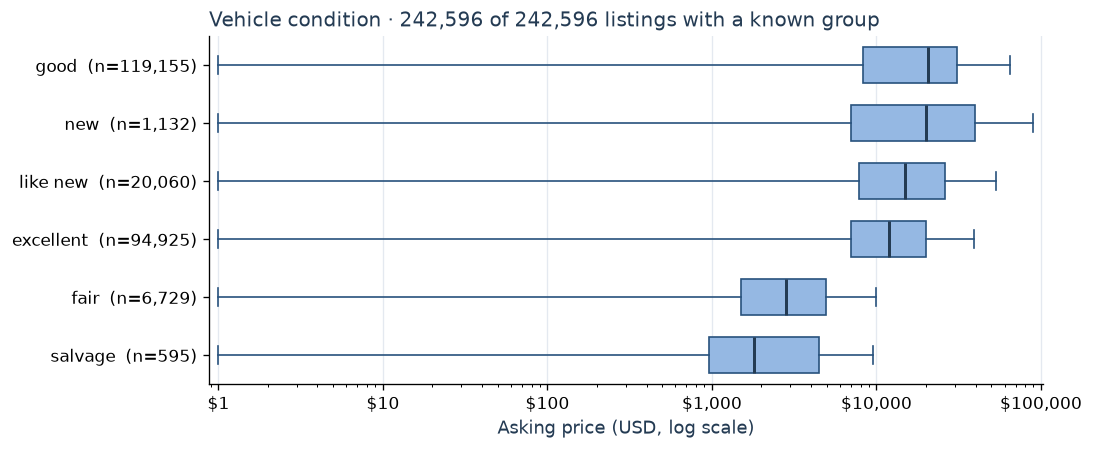

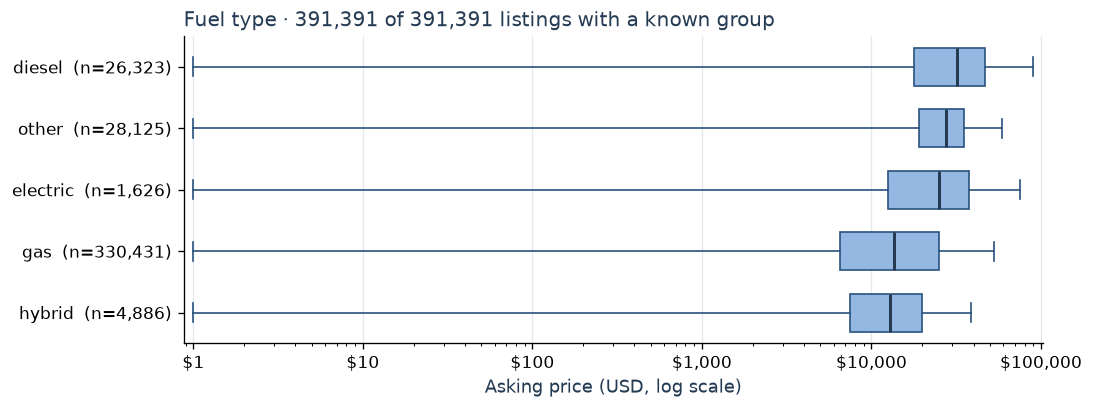

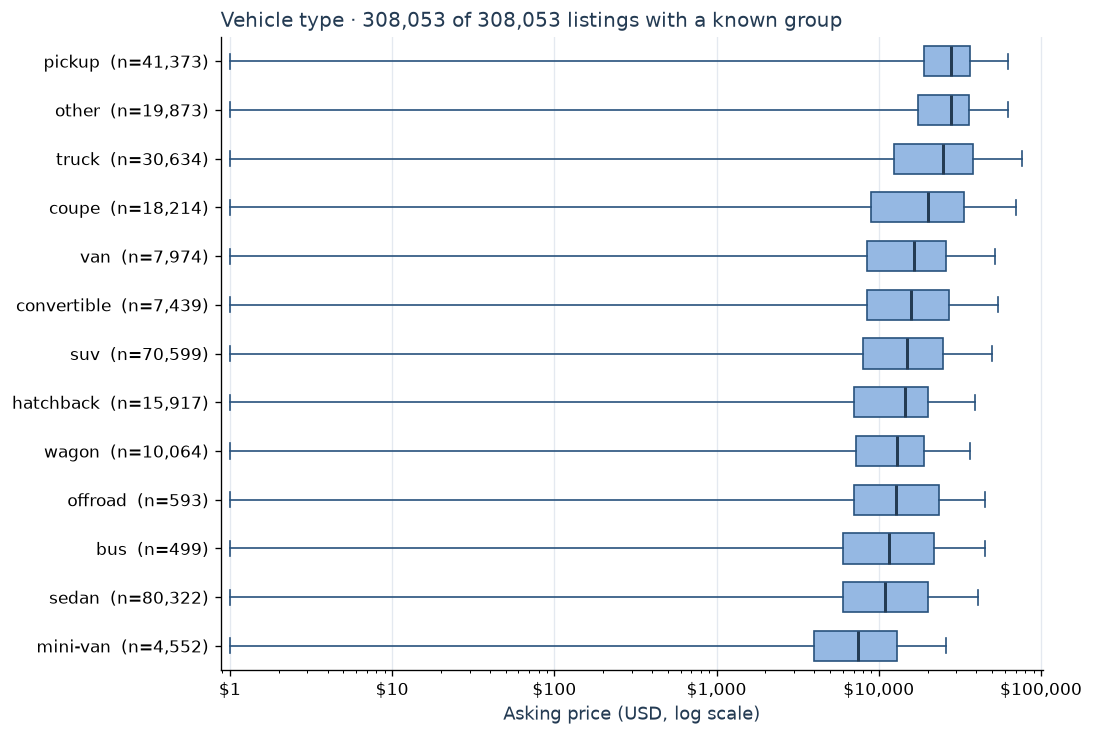

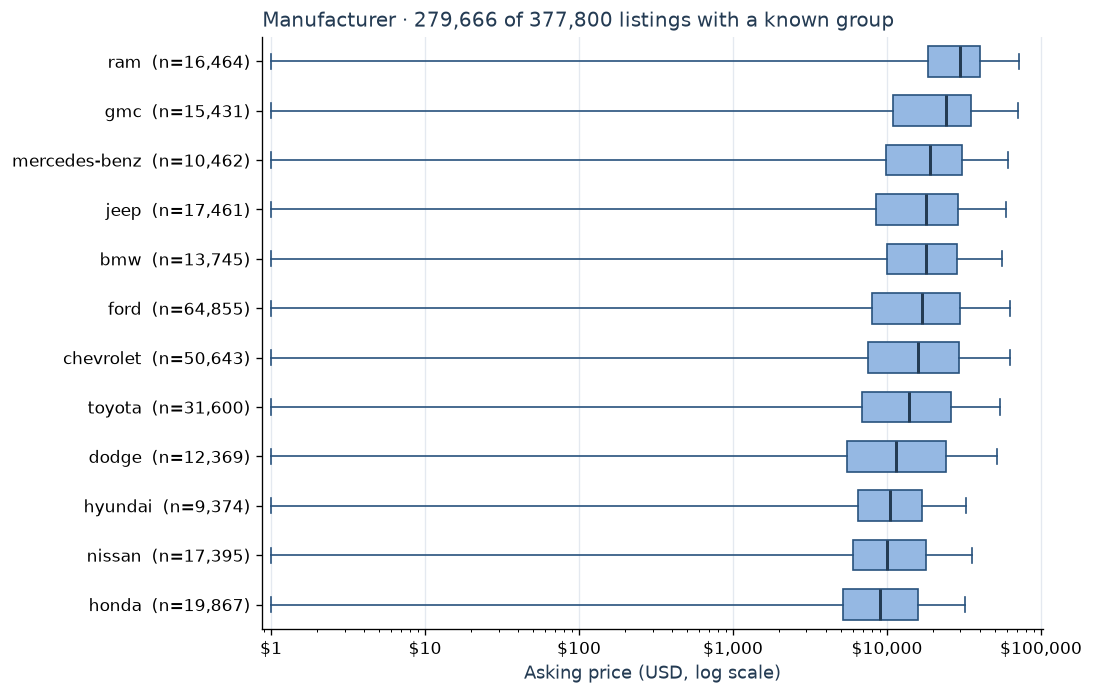

In [4]:
for column, label in CATEGORY_LABELS.items():
    groups = category_results[column]
    if not groups:
        print(f"{label}: no groups reach {MIN_CATEGORY_LISTINGS:,} listings.")
        continue

    stats = [box for box, _ in groups]
    displayed_n = sum(count for _, count in groups)
    fig, ax = plt.subplots(figsize=(9, max(3.1, 1.6 + 0.34 * len(stats))), layout="constrained")
    ax.bxp(
        stats, orientation="horizontal", showfliers=False, patch_artist=True, widths=0.62,
        boxprops={"facecolor": palette["fill"], "edgecolor": palette["outline"]},
        medianprops={"color": palette["text"], "linewidth": 1.8},
        whiskerprops={"color": palette["outline"]},
        capprops={"color": palette["outline"]},
    )
    ax.set_xscale("log")
    ax.set_xlim(category_xlim)
    ax.xaxis.set_major_formatter(dollars)
    ax.set_xlabel("Asking price (USD, log scale)")
    ax.set_title(
        f"{label} · {displayed_n:,} of {group_available[column]:,} listings with a known group",
        loc="left", fontsize=12,
    )
    ax.grid(axis="x", color=palette["grid"])
    ax.set_axisbelow(True)
    plt.show()

## Compare median asking prices by state

Use the listings with a recognised two-letter state code or DC. Bars start at zero and are sorted by median asking price. The threshold limits comparisons based on small samples; it does not correct for differences in the kinds of vehicles listed.

In [5]:
states = (
    listings.groupby("state", observed=True, dropna=True)["price"]
    .agg(n="size", median_usd="median")
    .reset_index()
)
assert int(states["n"].sum()) == int(group_available["state"])
shown_states = states.loc[states["n"].ge(MIN_STATE_LISTINGS)].sort_values(
    ["median_usd", "state"], ascending=[True, False]
)
shown_state_n = shown_states["n"].sum()
print(
    f"Showing {len(shown_states):,} of {len(states):,} states or districts "
    f"with a valid code: {shown_state_n:,} of {group_available['state']:,} listings."
)

Showing 51 of 51 states or districts with a valid code: 393,985 of 393,985 listings.


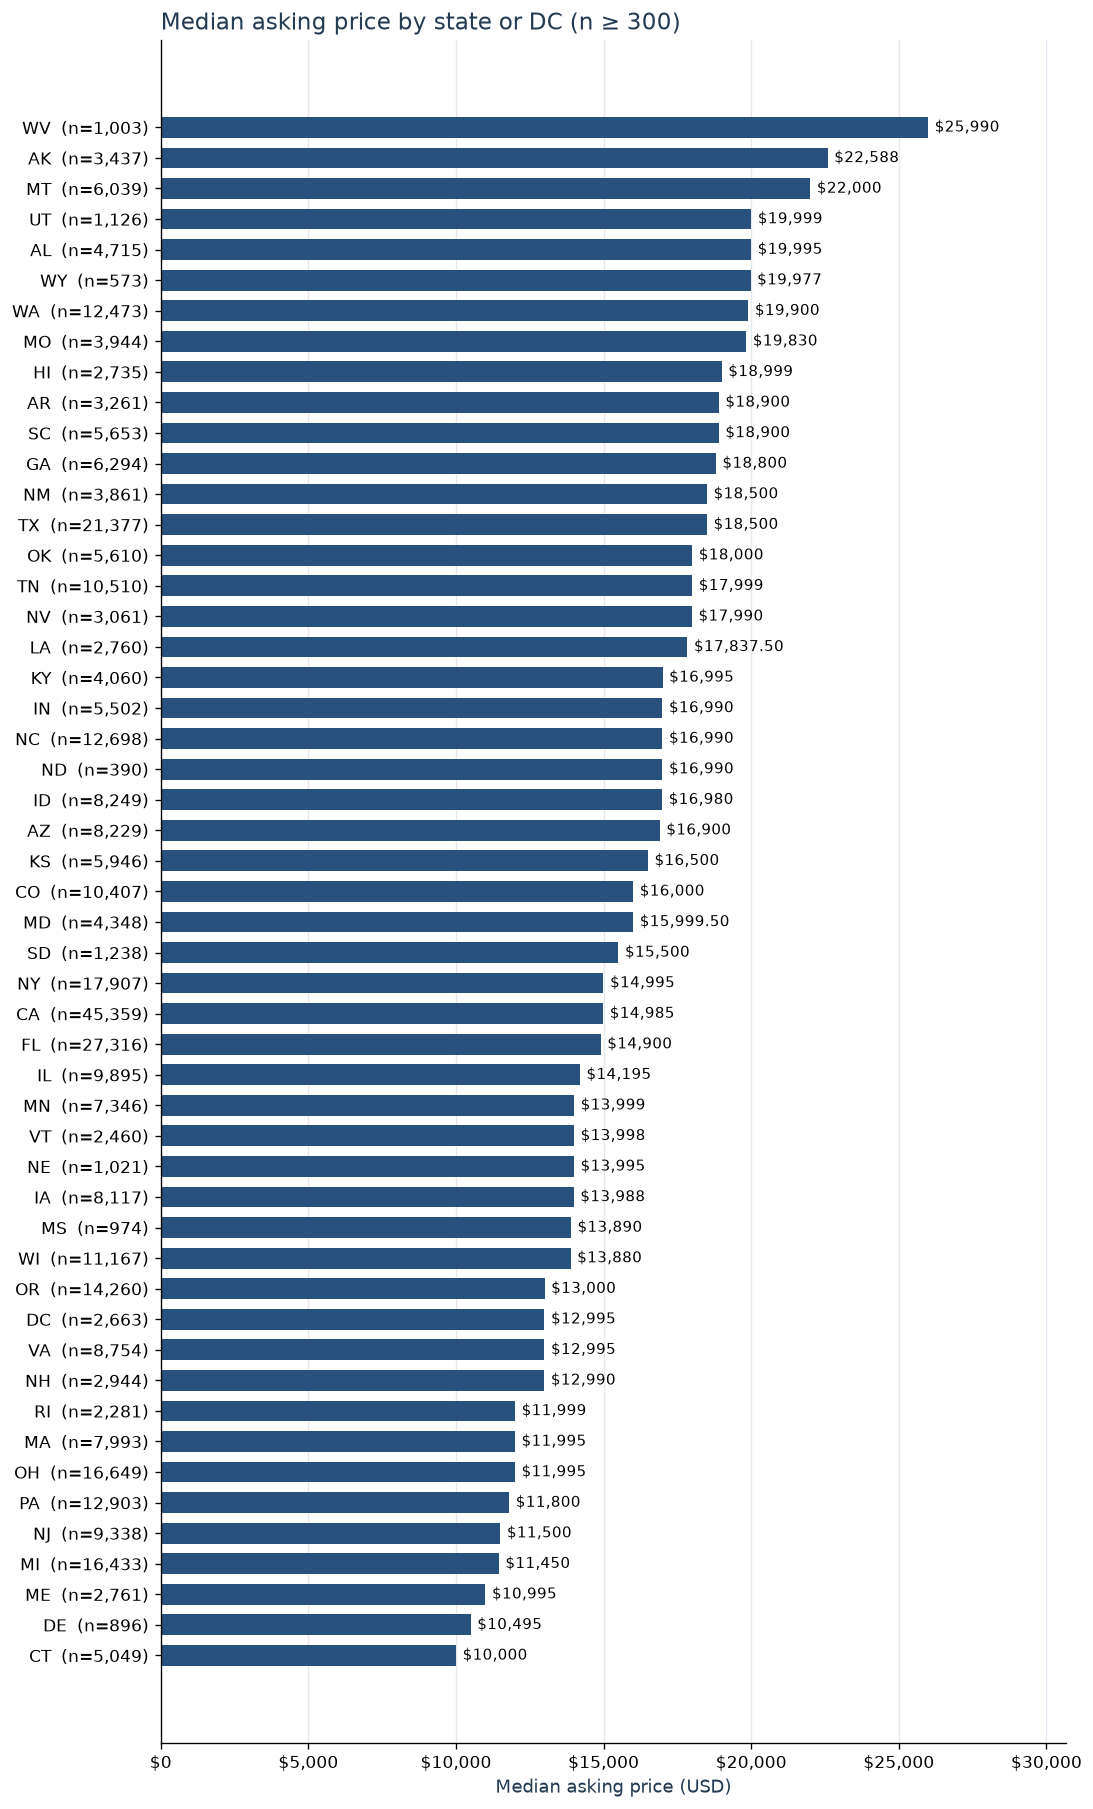

In [6]:
if shown_states.empty:
    print(f"No state or district reaches {MIN_STATE_LISTINGS:,} listings.")
else:
    fig, ax = plt.subplots(
        figsize=(9, max(3.0, 1.7 + 0.26 * len(shown_states))), layout="constrained"
    )
    labels = [f"{state}  (n={n:,})" for state, n in zip(shown_states["state"], shown_states["n"])]
    bars = ax.barh(labels, shown_states["median_usd"], color=palette["outline"], height=0.68)
    ax.bar_label(
        bars, labels=[f"${value:,.2f}".removesuffix(".00") for value in shown_states["median_usd"]],
        padding=4, fontsize=9,
    )
    ax.set_xlim(0, shown_states["median_usd"].max() * 1.18)
    ax.set_xlabel("Median asking price (USD)")
    ax.set_title(f"Median asking price by state or DC (n ≥ {MIN_STATE_LISTINGS:,})", loc="left")
    ax.xaxis.set_major_formatter(dollars)
    ax.grid(axis="x", color=palette["grid"])
    ax.set_axisbelow(True)
    plt.show()

## Interpret the comparison

Treat these as unadjusted associations within the Craigslist sample. Age, mileage, condition, manufacturer and other factors can vary across groups. Asking prices describe listings, and transaction prices would require a separate source.

In [7]:
if len(shown_states) >= 2:
    lowest, highest = shown_states.iloc[0], shown_states.iloc[-1]
    display(Markdown(
        f"Among the {len(shown_states)} eligible states or districts, median asking prices "
        f"ranged from **${lowest.median_usd:,.2f}** ({lowest.state}; n={lowest.n:,}) "
        f"to **${highest.median_usd:,.2f}** ({highest.state}; n={highest.n:,})."
    ))

Among the 51 eligible states or districts, median asking prices ranged from **$10,000.00** (CT; n=5,049) to **$25,990.00** (WV; n=1,003).